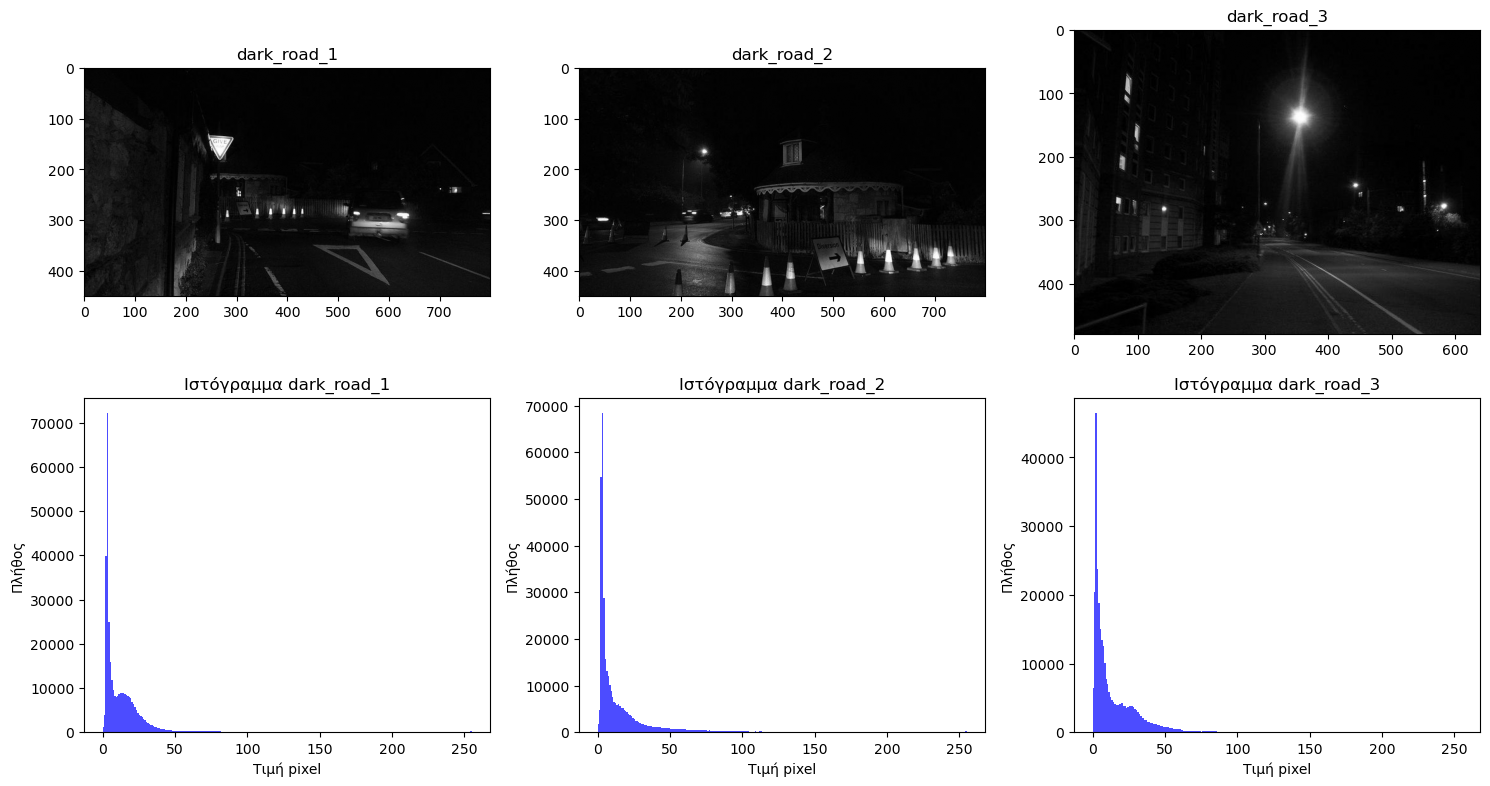

In [2]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Φόρτωση εικόνων
img1 = np.array(Image.open('dark_road_1.jpg').convert('L'), dtype=float)
img2 = np.array(Image.open('dark_road_2.jpg').convert('L'), dtype=float)
img3 = np.array(Image.open('dark_road_3.jpg').convert('L'), dtype=float)

# Εμφάνιση εικόνων και ιστογραμμάτων
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, (img, title) in enumerate(zip([img1, img2, img3], 
                                      ['dark_road_1', 'dark_road_2', 'dark_road_3'])):
    axes[0, i].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(title)
    
    axes[1, i].hist(img.ravel(), bins=256, range=(0, 255), color='blue', alpha=0.7)
    axes[1, i].set_title(f'Ιστόγραμμα {title}')
    axes[1, i].set_xlabel('Τιμή pixel')
    axes[1, i].set_ylabel('Πλήθος')

plt.tight_layout()
plt.show()

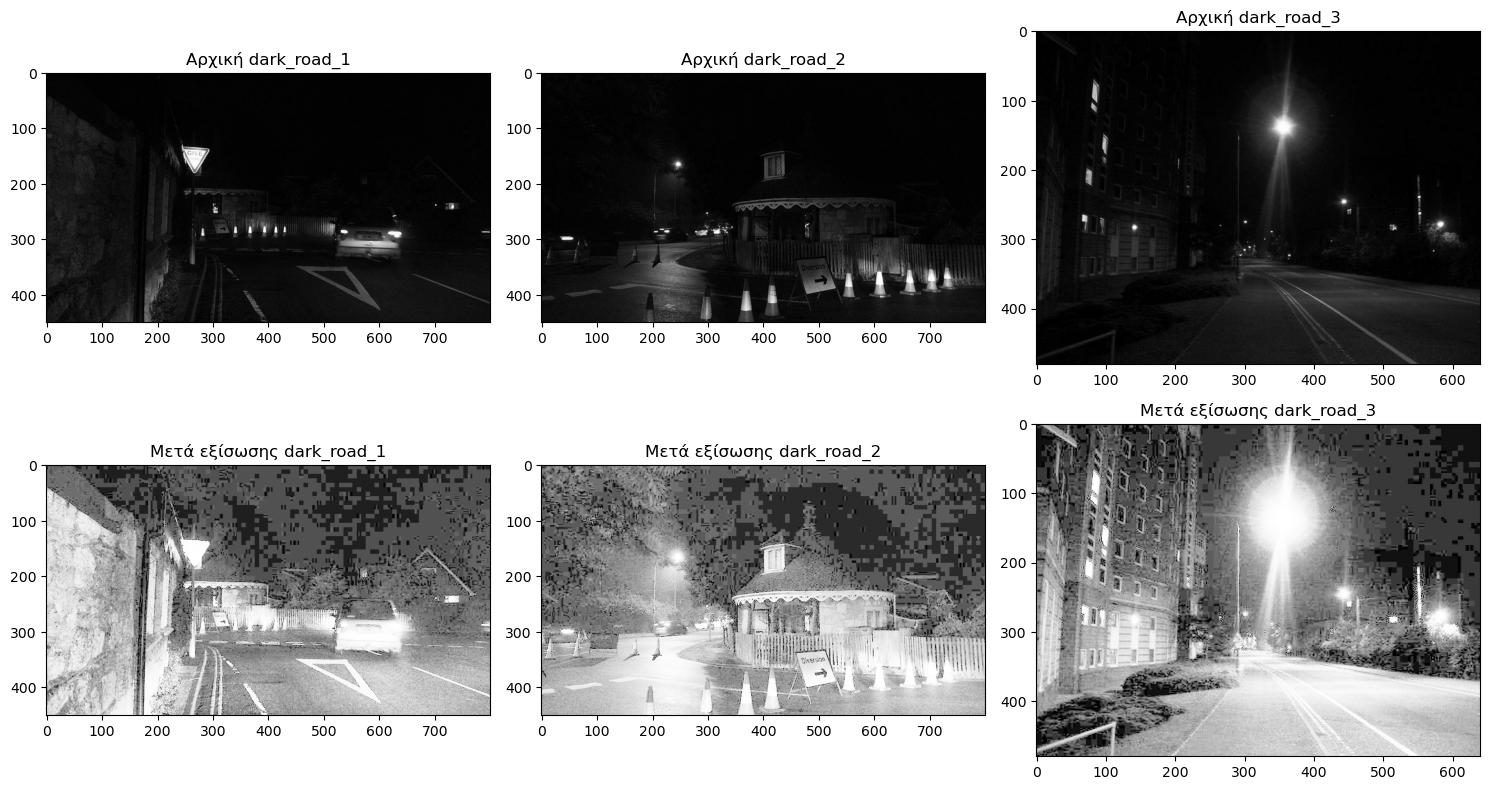

In [3]:
def histogram_equalization(img):
    img = img.astype(np.uint8)
    # Βήμα 1: ιστόγραμμα
    hist, bins = np.histogram(img.ravel(), bins=256, range=(0, 255))
    # Βήμα 2: αθροιστικό ιστόγραμμα (CDF)
    cdf = hist.cumsum()
    # Βήμα 3: κανονικοποίηση
    cdf_min = cdf[cdf > 0].min()
    total_pixels = img.size
    cdf_normalized = (cdf - cdf_min) / (total_pixels - cdf_min) * 255
    # Εφαρμογή στην εικόνα
    img_eq = cdf_normalized[img]
    return img_eq

# Εφαρμογή στις 3 εικόνες
img1_eq = histogram_equalization(img1)
img2_eq = histogram_equalization(img2)
img3_eq = histogram_equalization(img3)

# Εμφάνιση αρχικών και εξισωμένων
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, (orig, eq, title) in enumerate(zip(
        [img1, img2, img3],
        [img1_eq, img2_eq, img3_eq],
        ['dark_road_1', 'dark_road_2', 'dark_road_3'])):
    axes[0, i].imshow(orig, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(f'Αρχική {title}')
    
    axes[1, i].imshow(eq, cmap='gray', vmin=0, vmax=255)
    axes[1, i].set_title(f'Μετά εξίσωσης {title}')

plt.tight_layout()
plt.show()

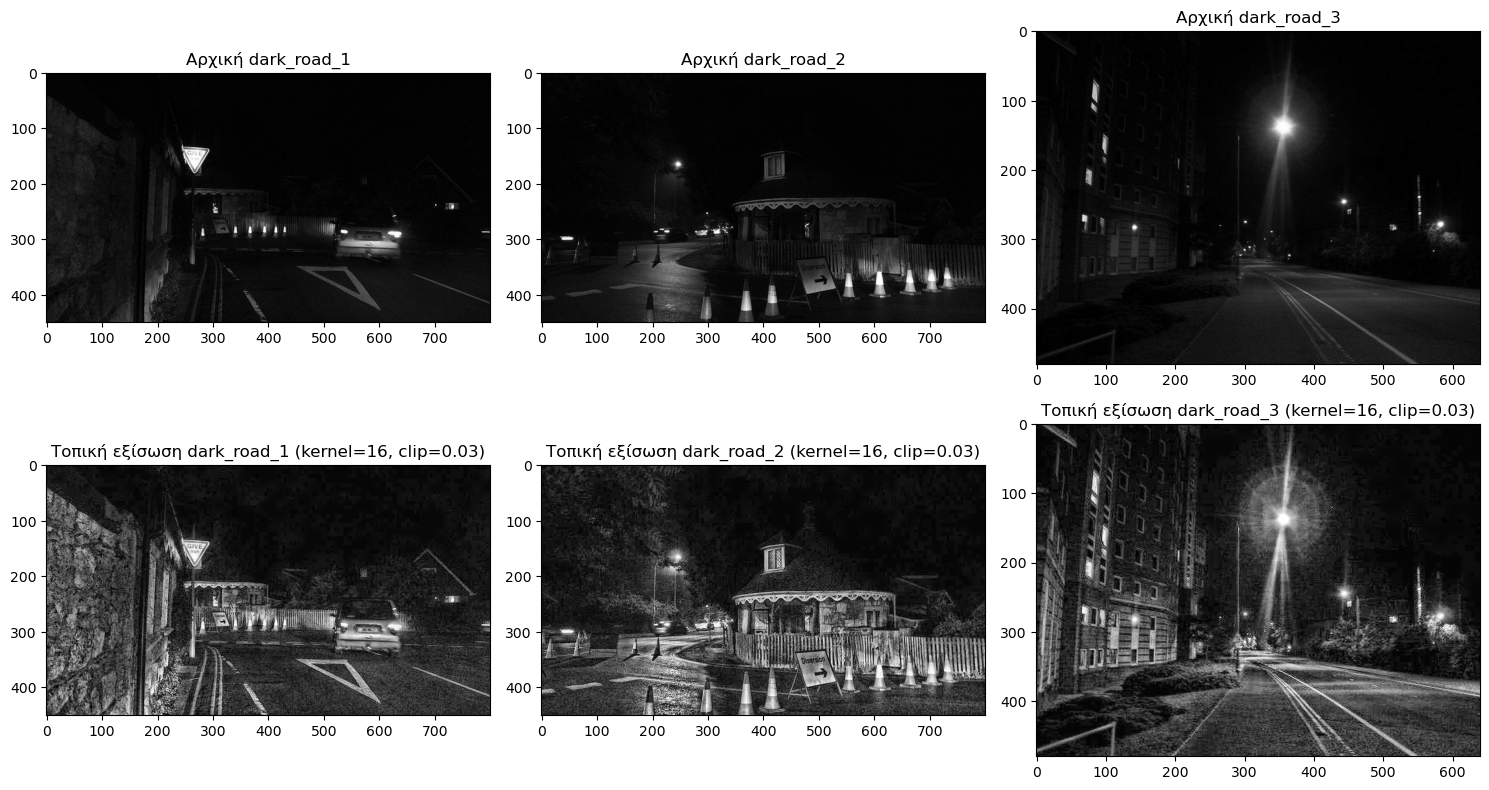

In [9]:
from skimage import exposure

# Εφαρμογή τοπικής εξίσωσης με διαφορετικά μεγέθη παραθύρου
# kernel_size: το μέγεθος του παραθύρου
img1_adapteq = exposure.equalize_adapthist(img1/255.0, kernel_size=16, clip_limit=0.03) * 255
img2_adapteq = exposure.equalize_adapthist(img2/255.0, kernel_size=16, clip_limit=0.03) * 255
img3_adapteq = exposure.equalize_adapthist(img3/255.0, kernel_size=16, clip_limit=0.03) * 255
# Εμφάνιση αρχικών και τοπικά εξισωμένων
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, (orig, eq, title) in enumerate(zip(
        [img1, img2, img3],
        [img1_adapteq, img2_adapteq, img3_adapteq],
        ['dark_road_1', 'dark_road_2', 'dark_road_3'])):
    axes[0, i].imshow(orig, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(f'Αρχική {title}')
    
    axes[1, i].imshow(eq, cmap='gray', vmin=0, vmax=255)
    axes[1, i].set_title(f'Τοπική εξίσωση {title} (kernel=16, clip=0.03)')

plt.tight_layout()
plt.show()

Θετικά:

Βλέπεις πολύ περισσότερες λεπτομέρειες — κτίρια, δέντρα, δρόμος, κώνοι
Η αντίθεση βελτιώθηκε σημαντικά
Δεν υπάρχει ο έντονος θόρυβος (τετραγωνάκια) που είχε η ολική εξίσωση

Αρνητικά:

Στην dark_road_3 γύρω από τον φανοστάτη υπάρχει ένα φωτεινό φαινόμενο (halo) — αυτό είναι χαρακτηριστικό της τοπικής εξίσωσης όταν υπάρχουν πολύ φωτεινά σημεία

Η ολική εξίσωση ιστογράμματος βελτιώνει σημαντικά την αντίθεση αλλά ενισχύει έντονα τον θόρυβο, δημιουργώντας ένα "τετραγωνισμένο" αποτέλεσμα, ειδικά στις σκοτεινές περιοχές. Αυτό συμβαίνει γιατί επεξεργάζεται όλη την εικόνα με τον ίδιο τρόπο χωρίς να λαμβάνει υπόψη τις τοπικές διαφορές φωτεινότητας. Η τοπική (adaptive) εξίσωση με kernel=16 και clip_limit=0.03 δίνει πολύ καλύτερα αποτελέσματα — αναδεικνύει λεπτομέρειες που δεν φαίνονταν στην αρχική εικόνα (κτίρια, δρόμος, κώνοι) με πολύ λιγότερο θόρυβο, καθώς προσαρμόζεται στο τοπικό περιεχόμενο κάθε περιοχής. Το μόνο της μειονέκτημα είναι ένα ελαφρύ halo effect γύρω από πολύ φωτεινά σημεία (π.χ. φανοστάτες).